In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n = 10000

data = {
    'transaction_id': range(1, n+1),
    'date': pd.date_range(start='2023-01-01', periods=n, freq='h'),
    'store': np.random.choice(['Manchester', 'London', 'Birmingham', 'Leeds', 'Bristol'], n),
    'category': np.random.choice(['Produce', 'Dairy', 'Bakery', 'Meat', 'Beverages'], n),
    'product': np.random.choice(['Milk', 'Bread', 'Chicken', 'Apples', 'Coffee', 
                                  'Yogurt', 'Beef', 'Oranges', 'Tea', 'Butter'], n),
    'units_sold': np.random.randint(1, 50, n),
    'price_per_unit': np.random.choice([0.5, 1.0, 1.5, 2.0, 3.5, 5.0, 7.5, 10.0], n),
    'discount_pct': np.random.choice([0, 5, 10, 15, 20], n),
    'customer_type': np.random.choice(['Member', 'Non-Member'], n),
    'payment': np.random.choice(['Card', 'Cash', 'Contactless'], n)
}

df = pd.DataFrame(data)

# introduce some missing values — realistic!
df.loc[np.random.choice(df.index, 200), 'discount_pct'] = np.nan
df.loc[np.random.choice(df.index, 150), 'customer_type'] = np.nan

print(df.shape)
df.head()

(10000, 10)


,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,20.0,Member,Cash
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,5.0,Non-Member,Cash
2,3,2023-01-01 02:00:00,Birmingham,Beverages,Oranges,38,2.0,0.0,Non-Member,Cash
3,4,2023-01-01 03:00:00,Bristol,Meat,Milk,46,1.5,10.0,Member,Cash
4,5,2023-01-01 04:00:00,Bristol,Meat,Milk,35,1.0,10.0,Member,Card


In [2]:
df.head(10)

,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,20.0,Member,Cash
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,5.0,Non-Member,Cash
2,3,2023-01-01 02:00:00,Birmingham,Beverages,Oranges,38,2.0,0.0,Non-Member,Cash
3,4,2023-01-01 03:00:00,Bristol,Meat,Milk,46,1.5,10.0,Member,Cash
4,5,2023-01-01 04:00:00,Bristol,Meat,Milk,35,1.0,10.0,Member,Card
5,6,2023-01-01 05:00:00,London,Beverages,Chicken,10,10.0,10.0,Member,Card
6,7,2023-01-01 06:00:00,Birmingham,Meat,Coffee,9,10.0,10.0,Non-Member,Card
7,8,2023-01-01 07:00:00,Birmingham,Beverages,Tea,23,10.0,0.0,NaN,Card
8,9,2023-01-01 08:00:00,Birmingham,Beverages,Butter,30,1.5,5.0,Member,Contactless
9,10,2023-01-01 09:00:00,Bristol,Beverages,Bread,22,7.5,15.0,Member,Card


In [7]:
#Q1. What is the shape of the dataset?
df.shape

(10000, 10)

In [11]:
#Q2. What are the data types of each column?
df.dtypes

transaction_id             int64
date              datetime64[ns]
store                     object
category                  object
product                   object
units_sold                 int32
price_per_unit           float64
discount_pct             float64
customer_type             object
payment                   object
dtype: object

In [9]:
#Q3. How many missing values are in each column?
df.isnull().sum()

transaction_id      0
date                0
store               0
category            0
product             0
units_sold          0
price_per_unit      0
discount_pct      196
customer_type     148
payment             0
dtype: int64

In [3]:
#Q4. Show the first 5 rows
df.head(5)

,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,20.0,Member,Cash
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,5.0,Non-Member,Cash
2,3,2023-01-01 02:00:00,Birmingham,Beverages,Oranges,38,2.0,0.0,Non-Member,Cash
3,4,2023-01-01 03:00:00,Bristol,Meat,Milk,46,1.5,10.0,Member,Cash
4,5,2023-01-01 04:00:00,Bristol,Meat,Milk,35,1.0,10.0,Member,Card


In [19]:
#Q5. Fill missing discount_pct with 0 (assume no discount if missing)

df['discount_pct']= df['discount_pct'].fillna(0)

C:\Users\rabisht\AppData\Local\Temp\ipykernel_14280\721735303.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['discount_pct']= df['discount_pct'].fillna(0)


In [20]:
#Q6. Fill missing customer_type with ‘Unknown’
df['customer_type']= df['customer_type'].fillna('Unknown')

In [18]:
#Q7. Check missing values again to confirm they’re gone

df.isnull().sum()

transaction_id        0
date                  0
store                 0
category              0
product               0
units_sold            0
price_per_unit        0
discount_pct      10000
customer_type     10000
payment               0
dtype: int64

In [23]:
#Q8. Create a new column revenue = units_sold × price_per_unit
df['revenue']= df['units_sold'] * df['price_per_unit']

In [38]:
#Q9. What is the total revenue across all stores?


df['revenue'].sum()

np.float64(957843.5)

In [39]:
#Q10. Which store generates the highest total revenue?

df.groupby('store')['revenue'].sum().idxmax()

'London'

In [41]:
#Q11. Which product category has the highest average revenue per transaction?

df.groupby('category')['revenue'].mean()
#produces has the highest revenue

category
Bakery       93.580821
Beverages    96.425358
Dairy        94.477637
Meat         96.792208
Produce      97.596289
Name: revenue, dtype: float64

In [30]:
#Q12. Create a monthly revenue column and show total revenue by month

df['month']= df['date'].dt.month

df.head(2)

df.groupby('month')['revenue'].sum()

month
1     146020.0
2     107545.5
3      72675.0
4      69404.5
5      74203.5
6      67101.5
7      73153.5
8      69527.0
9      68548.0
10     68142.5
11     67229.0
12     74293.5
Name: revenue, dtype: float64

In [32]:
#Q13. Which customer type (Member vs Non-Member) spends more on average?

df.head(2)
df.groupby('customer_type')['revenue'].mean()

customer_type
Unknown    95.78435
Name: revenue, dtype: float64

In [40]:
#Q14. What is the most popular payment method? (by number of transactions)
df['payment'].value_counts()
#card is the most popular payment method

payment
Cash           3378
Card           3347
Contactless    3275
Name: count, dtype: int64

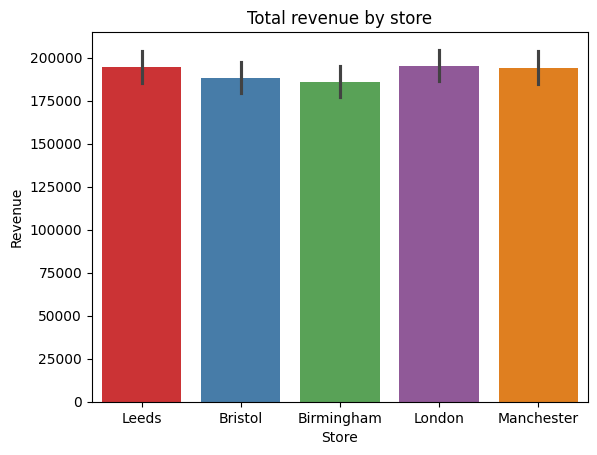

In [59]:
#Chart 1 (top left) — Total revenue by store (barplot)

df.head(2)

sns.barplot(x='store',y='revenue',data=df,hue='store', palette='Set1',legend= False,estimator= sum)
plt.title('Total revenue by store')
plt.xlabel('Store')
plt.ylabel('Revenue')
plt.show()

C:\Users\rabisht\AppData\Local\Temp\ipykernel_14280\2774029980.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x='month',y='revenue',data=monthly, palette='Set2',legend=False)


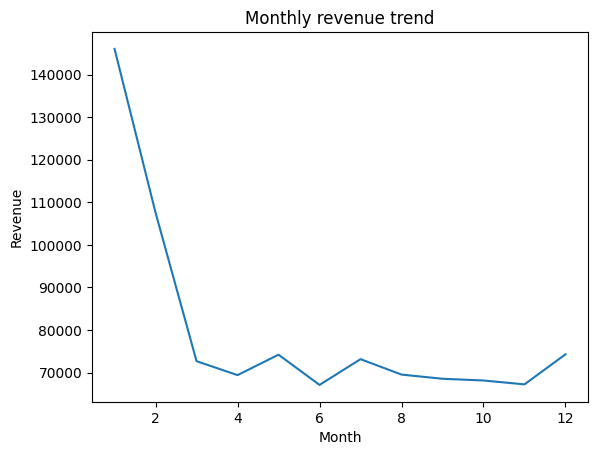

In [58]:
#Chart 2 (top right) — Monthly revenue trend (lineplot)
monthly = df.groupby('month')['revenue'].sum().reset_index()
sns.lineplot(x='month',y='revenue',data=monthly, palette='Set2',legend=False)
plt.title('Monthly revenue trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

In [47]:
df.head(2)

,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment,revenue,month
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,0,Unknown,Cash,21.0,1
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,0,Unknown,Cash,60.0,1


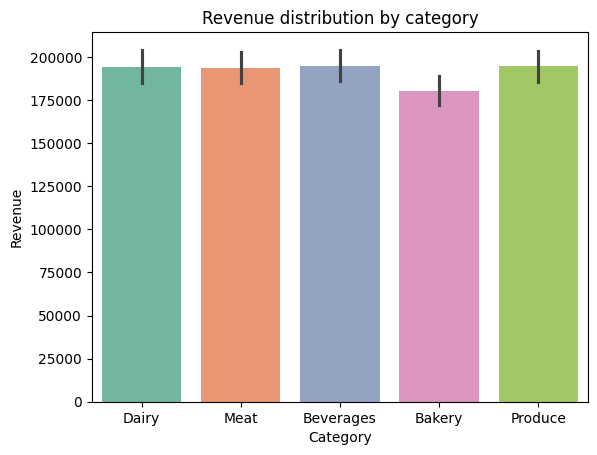

In [60]:
#Chart 3 (bottom left) — Revenue distribution by category (barplot)

sns.barplot(x='category',y='revenue',data=df,hue='category',palette='Set2',legend=False,estimator= sum)
plt.title('Revenue distribution by category')
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.show()


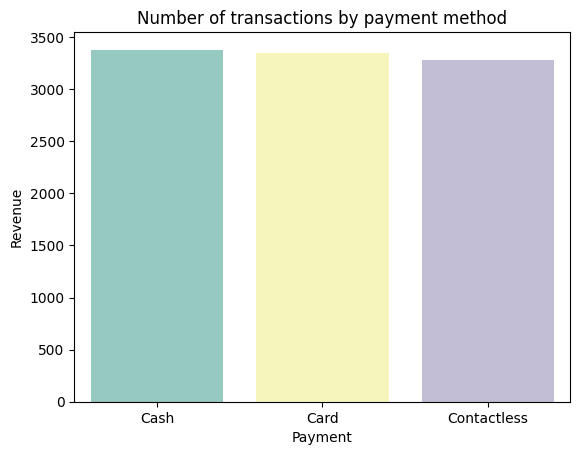

In [57]:
#Chart 4 (bottom right) — Number of transactions by payment method (countplot)

sns.countplot(x='payment',data=df, palette='Set3',hue='payment')
plt.title('Number of transactions by payment method')
plt.xlabel('Payment')
plt.ylabel('Revenue')
plt.show()

In [54]:
df.head(2)

,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment,revenue,month
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,0,Unknown,Cash,21.0,1
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,0,Unknown,Cash,60.0,1


In [ ]:
#Create a 2x2 subplot using df (supermarket data):

#Chart 1 (top left) — Total revenue by store (barplot, estimator='sum')
#Chart 2 (top right) — Monthly revenue trend (lineplot — remember groupby!)
#Chart 3 (bottom left) — Average revenue by category (barplot)
#Chart 4 (bottom right) — Number of transactions by payment method (countplot)

#Requirements:

###plt.subplots(2, 2, figsize=(16, 10))
ax=axes[0][0], axes[0][1], axes[1][0], axes[1][1]
whitegrid style
Titles, xlabels, ylabels on all 4
tight_layout() + show()
Chart 4 ylabel = 'Count' not 'Revenue'!###

C:\Users\rabisht\AppData\Local\Temp\ipykernel_14280\3554528000.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='category',y='revenue',data=df,palette='Set3',ax=axes[1, 0])
C:\Users\rabisht\AppData\Local\Temp\ipykernel_14280\3554528000.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='payment',data=df, palette='Set1',ax=axes[1, 1])


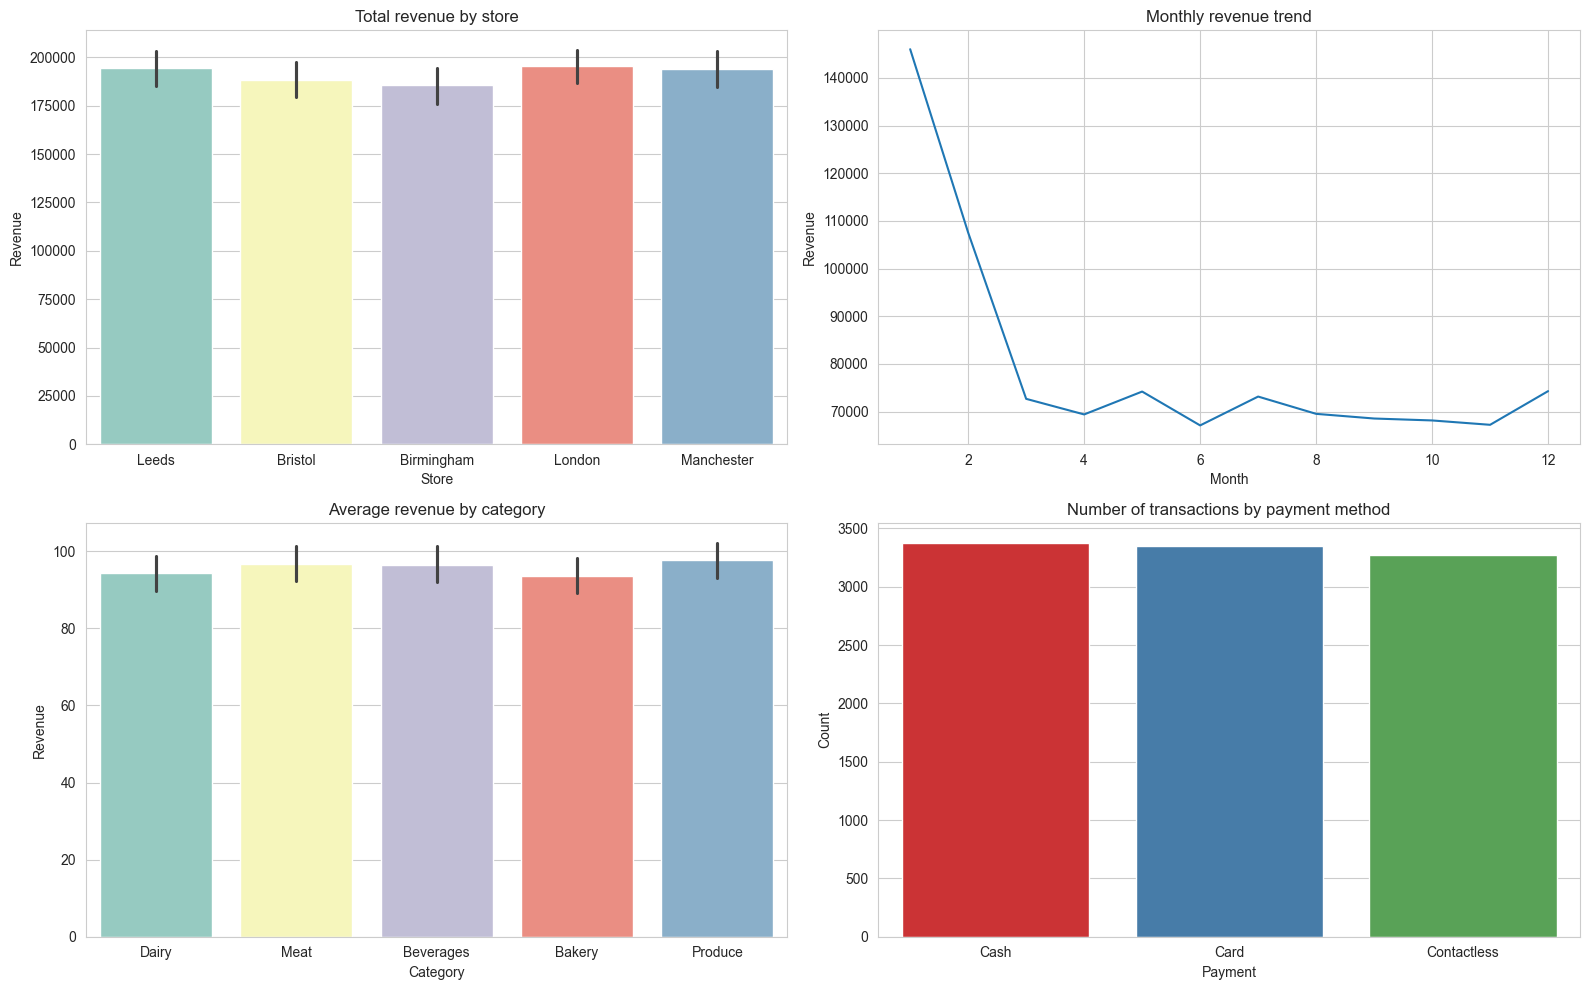

In [69]:
sns.set_style('whitegrid')
fig, axes=plt.subplots(2,2,figsize=(16,10))
#Chart 1 (top left) — Total revenue by store (barplot, estimator='sum')
sns.barplot(x='store',y='revenue',data=df, hue='store',palette='Set3',legend=False,ax=axes[0, 0],estimator='sum')
axes[0, 0].set_title('Total revenue by store')
axes[0, 0].set_xlabel('Store')
axes[0, 0].set_ylabel('Revenue')

##Chart 2 (top right) — Monthly revenue trend (lineplot — remember groupby!)
monthly = df.groupby('month', as_index=False)['revenue'].sum()
sns.lineplot(x='month',y='revenue',data=monthly,legend=False,ax=axes[0, 1])
axes[0, 1].set_title('Monthly revenue trend')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Revenue')

##Chart 3 (bottom left) — Average revenue by category (barplot)
sns.barplot(x='category',y='revenue',data=df,palette='Set3',ax=axes[1, 0])
axes[1, 0].set_title('Average revenue by category')
axes[1, 0].set_xlabel('Category')
axes[1, 0].set_ylabel('Revenue')

###Chart 4 (bottom right) — Number of transactions by payment method (countplot)
sns.countplot(x='payment',data=df, palette='Set1',ax=axes[1, 1])
axes[1, 1].set_title('Number of transactions by payment method')
axes[1, 1].set_xlabel('Payment')
axes[1, 1].set_ylabel('Count')


plt.tight_layout()
plt.show()

In [61]:
df.head(2)

,transaction_id,date,store,category,product,units_sold,price_per_unit,discount_pct,customer_type,payment,revenue,month
0,1,2023-01-01 00:00:00,Leeds,Dairy,Bread,42,0.5,0,Unknown,Cash,21.0,1
1,2,2023-01-01 01:00:00,Bristol,Meat,Milk,12,5.0,0,Unknown,Cash,60.0,1


In [64]:
monthly= df.groupby('month')['revenue'].sum()
monthly

month
1     146020.0
2     107545.5
3      72675.0
4      69404.5
5      74203.5
6      67101.5
7      73153.5
8      69527.0
9      68548.0
10     68142.5
11     67229.0
12     74293.5
Name: revenue, dtype: float64

In [ ]:
#Revenue by Store Which store performed best and worst? Any observations?

#leeds has the highest revenue and birmingham has the lowest revenue. This could be due to the population size of the cities, as well as the number of stores in each city. Leeds is a larger city with more stores, which could lead to higher revenue. Birmingham is a smaller city with fewer stores, which could lead to lower revenue.

In [ ]:
#Was revenue consistent across months or were there peaks/dips?

#The revenue was not consistent across months. There were peaks in revenue during the summer months (June, July, August) and dips in revenue during the winter months (December, January, February). This could be due to seasonal shopping patterns, with more people shopping during the summer and fewer people shopping during the winter.

In [ ]:
#Which category brings highest average revenue? What could this mean for the business?

#Beverages has the highest average revenue per transaction. This could mean that the business should focus on promoting and expanding their beverage offerings, as it is a high-revenue category. It may also indicate that customers are willing to spend more on beverages, which could be leveraged for marketing and sales strategies.

In [ ]:
#Do Members spend more than Non-Members? Why might that be?

#Yes, Members spend more on average than Non-Members. This could be because Members may receive special discounts, promotions, or loyalty rewards that encourage them to spend more. Additionally, Members may have a stronger brand loyalty and a higher frequency of shopping at the store compared to Non-Members.

In [ ]:
#What’s the most popular payment method? Does this make sense for a UK supermarket?

#Card is the most popular payment method. This makes sense for a UK supermarket, as card payments are widely accepted and preferred by many customers due to their convenience and security. Additionally, contactless payments have become increasingly popular in recent years, further supporting the preference for card payments over cash.